# 01 - Data Cleaning & Exploratory Data Analysis

**Objective**: Clean the raw network logs and perform comprehensive EDA.

**Deliverables**:
- `data/clean_network_logs.parquet`
- `data/quarantine_logs.parquet`
- `reports/eda_summary.md`


In [1]:
import sys
sys.path.insert(0, '../')
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy import stats as sps
from scipy.stats import chi2_contingency
from data.cleaning import clean_network_logs, compute_file_hash

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
plt.style.use('seaborn-v0_8-whitegrid')
print('Environment ready')


Environment ready


## 1. Load Raw Data


In [2]:
raw_df = pd.read_csv('../network_logs_dirty.csv')
print('Raw shape:', raw_df.shape)
print('Columns:', list(raw_df.columns))
print('Memory (MB):', round(raw_df.memory_usage(deep=True).sum() / 1024**2, 1))
raw_df.head()


Raw shape: (10300, 9)
Columns: ['timestamp', 'src_ip', 'dst_ip', 'port', 'bytes', 'protocol', 'status', 'label', 'anomaly_type']
Memory (MB): 5.0


,timestamp,src_ip,dst_ip,port,bytes,protocol,status,label,anomaly_type
0,2024-05-31 10:46:50,223.243.76.173,67.185.25.227,993,5398309.0,SSH,SUCCESS,benign,NaN
1,2024-09-14 20:56:20,192.168.111.161,130.139.125.61,22025,1761148.0,HTTPS,ERROR,benign,NaN
2,2024-09-02 18:01:25,192.168.140.105,74.42.200.38,3216,6963727.0,TCP,REFUSED,benign,NaN
3,2024-06-18 07:59:20,59.90.53.140,171.197.54.33,59672,7373410.0,TCP,RESET,benign,NaN
4,2024-03-20 11:22:40,217.31.150.166,129.141.214.78,443,4991182.0,HTTP,TIMEOUT,benign,NaN


## 2. Data Quality Assessment


In [3]:
missing = raw_df.isnull().sum()
missing_pct = (missing / len(raw_df) * 100).round(2)
print('=== Missing values ===')
print(pd.DataFrame({'missing': missing, 'pct': missing_pct}).sort_values('pct', ascending=False))
print()
print('Full-row duplicates:', raw_df.duplicated().sum())
if all(col in raw_df.columns for col in ['timestamp', 'src_ip', 'dst_ip', 'port']):
    print('Composite-key duplicates:', raw_df.duplicated(subset=['timestamp', 'src_ip', 'dst_ip', 'port']).sum())
print()
print('=== Target distribution ===')
print(raw_df['label'].value_counts(normalize=True).round(4))


=== Missing values ===
              missing    pct
anomaly_type     9898  96.10
status            234   2.27
timestamp          62   0.60
port               42   0.41
src_ip             41   0.40
dst_ip             40   0.39
bytes              35   0.34
protocol            0   0.00
label               0   0.00

Full-row duplicates: 280
Composite-key duplicates: 288

=== Target distribution ===
label
benign       0.9519
malicious    0.0481
Name: proportion, dtype: float64


## 3. Run Cleaning Pipeline

**Note**: `clean_network_logs` returns a `CleaningStats` object. We name it `clean_stats` to avoid
shadowing the `scipy.stats` module.


In [4]:
batch_id = compute_file_hash(Path('../network_logs_dirty.csv'))
print('Batch ID:', batch_id)

clean_df, quarantine_df, clean_stats = clean_network_logs(raw_df, batch_id)

print()
print('=== Cleaning Stats ===')
print('Total input:', clean_stats.total_input)
print('Total clean:', clean_stats.total_clean)
print('Total quarantined:', clean_stats.total_quarantined)
print('Clean ratio:', str(round(clean_stats.clean_ratio * 100, 2)) + '%')
print()
print('Rejection reasons:')
for reason, count in clean_stats.rejection_counts.items():
    print('  ', reason, ':', count)


Batch ID: c9d80a0be9cb4006

=== Cleaning Stats ===
Total input: 10300
Total clean: 9437
Total quarantined: 986
Clean ratio: 91.62%

Rejection reasons:
   DUPLICATE_RECORD : 288
   INVALID_IP : 166
   INVALID_TIMESTAMP : 134
   INVALID_PORT : 125
   MISSING_REQUIRED_FIELD : 123
   TIMESTAMP_OUT_OF_RANGE : 100
   NEGATIVE_BYTES : 50


## 4. Clean Data Overview


In [5]:
print('Clean shape:', clean_df.shape)
print('Columns:', list(clean_df.columns))
print()
print('=== Dtypes ===')
print(clean_df.dtypes)
print()
clean_df.describe(include='all').T


Clean shape: (9437, 12)
Columns: ['timestamp', 'src_ip', 'dst_ip', 'port', 'bytes', 'protocol', 'status', 'label', 'anomaly_type', 'bytes_clean', 'status_clean', 'event_timestamp']

=== Dtypes ===
timestamp                       object
src_ip                          object
dst_ip                          object
port                            object
bytes                          float64
protocol                        object
status                          object
label                           object
anomaly_type                    object
bytes_clean                    float64
status_clean                    object
event_timestamp    datetime64[ns, UTC]
dtype: object



,count,unique,top,freq,mean,min,25%,50%,75%,max,std
timestamp,9437,9382,2024/01/01 12:00:00,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
src_ip,9437,9392,192.168.213.49,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dst_ip,9437,9429,155.234.155.199,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
port,9437,4993,25,304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bytes,9402.0,NaN,NaN,NaN,5199399.336205,284.0,2538976.5,5186707.0,7816172.75,10485481.0,3029413.187997
protocol,9437,8,DNS,1208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,9205,6,SUCCESS,1611,NaN,NaN,NaN,NaN,NaN,NaN,NaN
label,9437,2,benign,8978,NaN,NaN,NaN,NaN,NaN,NaN,NaN
anomaly_type,368,4,brute_force,104,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bytes_clean,9437.0,NaN,NaN,NaN,5199352.262795,284.0,2544554.0,5186707.0,7811304.0,10485481.0,3023789.718958


## 5. Exploratory Data Analysis

### 5.1 Temporal Patterns


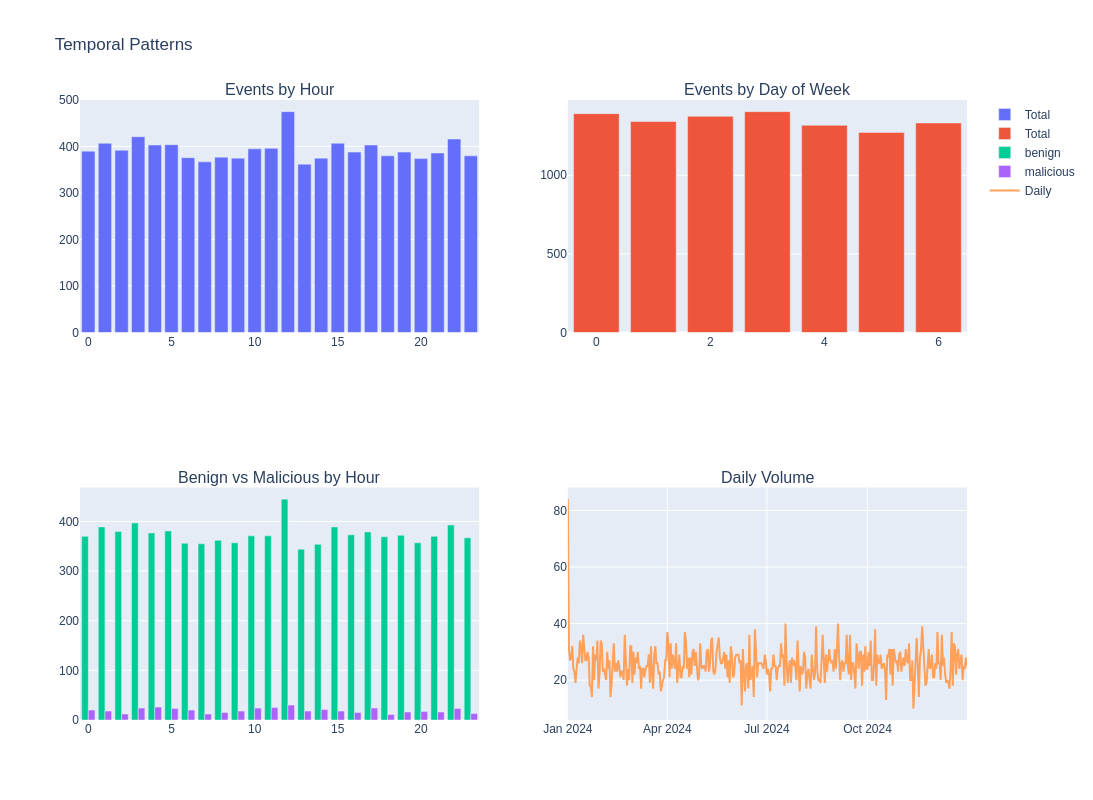

In [6]:
clean_df['hour'] = clean_df['event_timestamp'].dt.hour
clean_df['day_of_week'] = clean_df['event_timestamp'].dt.dayofweek
clean_df['date'] = clean_df['event_timestamp'].dt.date

fig = make_subplots(rows=2, cols=2, subplot_titles=(
    'Events by Hour', 'Events by Day of Week',
    'Benign vs Malicious by Hour', 'Daily Volume'))

hourly = clean_df.groupby('hour').size()
fig.add_trace(go.Bar(x=hourly.index, y=hourly.values, name='Total'), row=1, col=1)

dow = clean_df.groupby('day_of_week').size()
fig.add_trace(go.Bar(x=dow.index, y=dow.values, name='Total'), row=1, col=2)

hl = clean_df.groupby(['hour', 'label']).size().unstack(fill_value=0)
for col in hl.columns:
    fig.add_trace(go.Bar(x=hl.index, y=hl[col], name=col), row=2, col=1)

daily = clean_df.groupby('date').size()
fig.add_trace(go.Scatter(x=daily.index, y=daily.values, mode='lines', name='Daily'), row=2, col=2)

fig.update_layout(height=800, showlegend=True, title_text='Temporal Patterns')
fig.show()


### 5.2 Protocol & Port Analysis


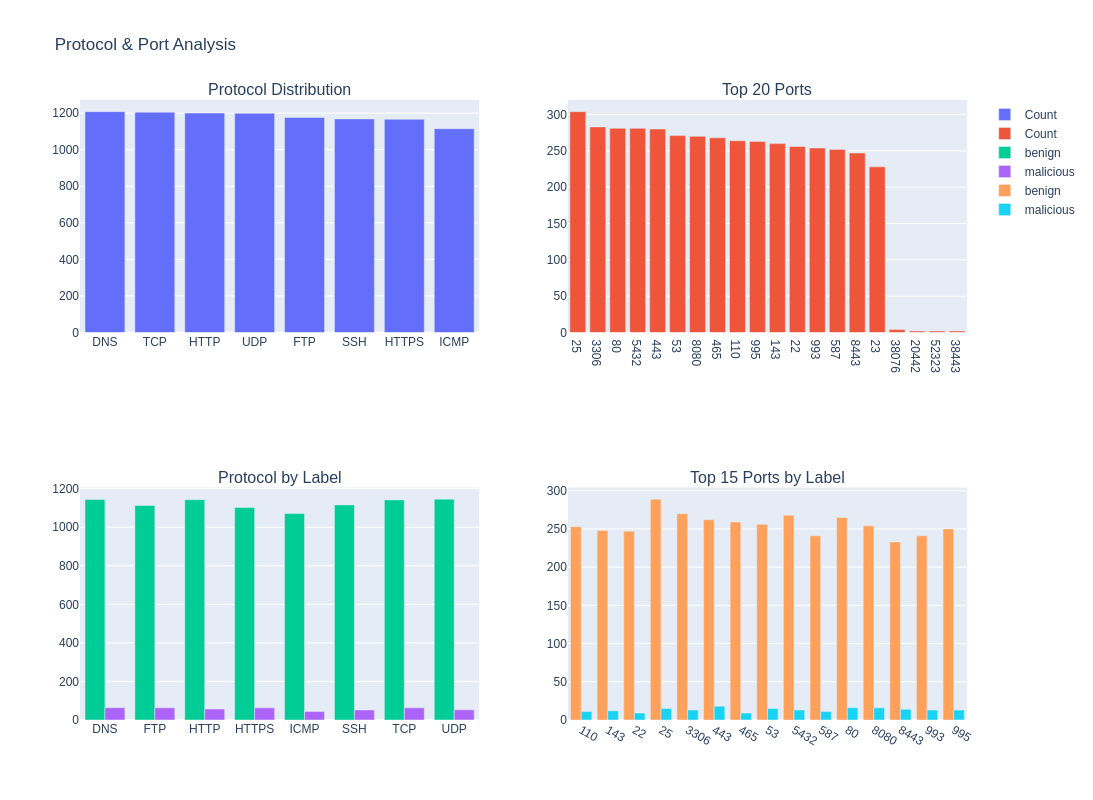

In [7]:
fig = make_subplots(rows=2, cols=2, subplot_titles=(
    'Protocol Distribution', 'Top 20 Ports',
    'Protocol by Label', 'Top 15 Ports by Label'))

proto_counts = clean_df['protocol'].value_counts()
fig.add_trace(go.Bar(x=proto_counts.index, y=proto_counts.values, name='Count'), row=1, col=1)

top_ports = clean_df['port'].value_counts().head(20)
fig.add_trace(go.Bar(x=top_ports.index.astype(str), y=top_ports.values, name='Count'), row=1, col=2)

pl = clean_df.groupby(['protocol', 'label']).size().unstack(fill_value=0)
for col in pl.columns:
    fig.add_trace(go.Bar(x=pl.index, y=pl[col], name=col), row=2, col=1)

top15 = clean_df['port'].value_counts().head(15).index
pt = clean_df[clean_df['port'].isin(top15)].groupby(['port', 'label']).size().unstack(fill_value=0)
for col in pt.columns:
    fig.add_trace(go.Bar(x=pt.index.astype(str), y=pt[col], name=col), row=2, col=2)

fig.update_layout(height=800, showlegend=True, title_text='Protocol & Port Analysis')
fig.show()


### 5.3 Bytes Transferred Analysis


In [8]:
fig = make_subplots(rows=1, cols=2, subplot_titles=(
    'Bytes Distribution (log1p scale)', 'Bytes by Label'))

for lab in ['benign', 'malicious']:
    d = clean_df[clean_df['label'] == lab]['bytes_clean']
    fig.add_trace(go.Histogram(x=np.log1p(d), name=lab, opacity=0.7, nbinsx=50), row=1, col=1)

fig.add_trace(go.Box(x=clean_df['label'], y=clean_df['bytes_clean'], name='Bytes'), row=1, col=2)
fig.update_layout(height=400, showlegend=True, title_text='Bytes Transferred')
fig.show()


### 5.4 IP Behavior


In [9]:
src_stats = clean_df.groupby('src_ip').agg(
    count=('bytes_clean', 'size'),
    bytes_mean=('bytes_clean', 'mean'),
    unique_ports=('port', 'nunique'),
    unique_dst=('dst_ip', 'nunique'),
    malicious_rate=('label', lambda x: (x == 'malicious').mean())).reset_index()

print('Unique source IPs:', src_stats.shape[0])
print('Unique destination IPs:', clean_df['dst_ip'].nunique())
print()
print('Top 10 source IPs by volume:')
print(src_stats.nlargest(10, 'count')[['src_ip', 'count', 'malicious_rate', 'unique_ports', 'unique_dst']])


Unique source IPs: 9392
Unique destination IPs: 9429

Top 10 source IPs by volume:
               src_ip  count  malicious_rate  unique_ports  unique_dst
6737   192.168.213.49      3             0.0             3           3
326    10.128.255.140      2             0.0             2           2
1707    10.46.204.162      2             0.0             1           1
4476    172.25.105.64      2             0.0             1           1
5671  192.168.100.162      2             0.0             2           2
5718   192.168.106.80      2             0.0             2           2
5743   192.168.109.40      2             0.0             2           2
5810   192.168.115.72      2             0.0             2           2
5837  192.168.119.160      2             0.0             2           2
5863  192.168.121.219      2             0.0             2           2


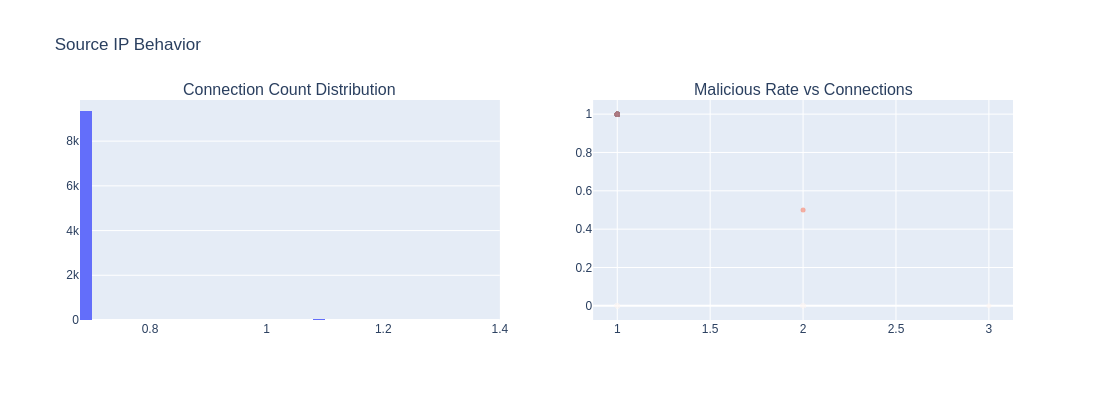

In [10]:
fig = make_subplots(rows=1, cols=2, subplot_titles=(
    'Connection Count Distribution', 'Malicious Rate vs Connections'))

fig.add_trace(go.Histogram(x=np.log1p(src_stats['count']), nbinsx=50, name='log1p(count)'), row=1, col=1)
fig.add_trace(go.Scatter(
    x=src_stats['count'], y=src_stats['malicious_rate'],
    mode='markers', opacity=0.5,
    marker=dict(size=5, color=src_stats['malicious_rate'], colorscale='Reds'),
    name='Malicious rate'), row=1, col=2)

fig.update_layout(height=400, showlegend=False, title_text='Source IP Behavior')
fig.show()


### 5.5 Anomaly Type Analysis


In [11]:
malicious = clean_df[clean_df['label'] == 'malicious']
benign = clean_df[clean_df['label'] == 'benign']

print('Malicious records:', len(malicious))
print()
print('Anomaly type distribution:')
print(malicious['anomaly_type'].value_counts())

anom_stats = malicious.groupby('anomaly_type').agg(
    count=('bytes_clean', 'size'),
    bytes_mean=('bytes_clean', 'mean'),
    bytes_median=('bytes_clean', 'median'),
    unique_src=('src_ip', 'nunique'),
    unique_dst=('dst_ip', 'nunique'),
    top_ports=('port', lambda x: x.value_counts().head(3).index.tolist())).reset_index()

print()
print('Anomaly type characteristics:')
print(anom_stats)


Malicious records: 459

Anomaly type distribution:
anomaly_type
ddos           5
brute_force    5
data_exfil     2
port_scan      1
Name: count, dtype: int64

Anomaly type characteristics:
  anomaly_type  count  bytes_mean  bytes_median  unique_src  unique_dst  \
0  brute_force      5   7022251.2     7097506.0           5           5   
1   data_exfil      2   5438874.0     5438874.0           2           2   
2         ddos      5   5631481.0     6087732.0           5           5   
3    port_scan      1   6409846.0     6409846.0           1           1   

               top_ports  
0  [32702, 23077, 14980]  
1          [8443, 35827]  
2  [65073, 38170, 24008]  
3                  [143]  


## 6. Statistical Tests

**Note**: We import `scipy.stats` as `sps` (alias) to avoid collision with the `clean_stats` object.


In [12]:
benign = clean_df[clean_df['label'] == 'benign']
malicious = clean_df[clean_df['label'] == 'malicious']

# Mann-Whitney U test for bytes
u_stat, p_value = sps.mannwhitneyu(benign['bytes_clean'], malicious['bytes_clean'], alternative='two-sided')
print('Bytes - Mann-Whitney U: U=' + str(int(u_stat)) + ', p=' + f'{p_value:.2e}')

# Chi-square for protocol
proto_table = pd.crosstab(clean_df['protocol'], clean_df['label'])
chi2, chi_p, dof, expected = chi2_contingency(proto_table)
print('Protocol - Chi2: chi2=' + str(round(chi2, 2)) + ', p=' + f'{chi_p:.2e}' + ', dof=' + str(dof))

# Chi-square for top ports
top_ports_set = clean_df['port'].value_counts().head(20).index
port_subset = clean_df[clean_df['port'].isin(top_ports_set)]
port_table = pd.crosstab(port_subset['port'], port_subset['label'])
chi2_p, chi2_pp, dof_p, _ = chi2_contingency(port_table)
print('Top 20 Ports - Chi2: chi2=' + str(round(chi2_p, 2)) + ', p=' + f'{chi2_pp:.2e}' + ', dof=' + str(dof_p))


Bytes - Mann-Whitney U: U=1989962, p=2.16e-01
Protocol - Chi2: chi2=5.19, p=6.37e-01, dof=7
Top 20 Ports - Chi2: chi2=7.69, p=9.89e-01, dof=19


## 7. Save Clean Data


In [13]:
pip install pyarrow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [14]:
Path('../data').mkdir(parents=True, exist_ok=True)
clean_df.to_parquet('../data/clean_network_logs.parquet', index=False)
quarantine_df.to_parquet('../data/quarantine_logs.parquet', index=False)
with open('../data/batch_meta.json', 'w') as f:
    json.dump({'batch_id': batch_id, 'clean_ratio': clean_stats.clean_ratio}, f)
print('Saved clean:', len(clean_df))
print('Saved quarantine:', len(quarantine_df))


Saved clean: 9437
Saved quarantine: 986


## 8. EDA Summary Report


In [15]:
lines = [
    '# EDA Summary Report', '',
    '## Dataset Overview',
    '- Total records: ' + str(len(raw_df)),
    '- Clean records: ' + str(len(clean_df)) + ' (' + str(round(clean_stats.clean_ratio * 100, 1)) + '%)',
    '- Quarantined: ' + str(len(quarantine_df)),
    '- Time range: ' + str(clean_df['event_timestamp'].min()) + ' to ' + str(clean_df['event_timestamp'].max()),
    '', '## Data Quality Issues',
]
for reason, count in clean_stats.rejection_counts.items():
    lines.append('- ' + reason + ': ' + str(count) + ' records')

lines += [
    '', '## Target Distribution',
    '- Benign: ' + str(len(benign)) + ' (' + str(round(len(benign) / len(clean_df) * 100, 1)) + '%)',
    '- Malicious: ' + str(len(malicious)) + ' (' + str(round(len(malicious) / len(clean_df) * 100, 1)) + '%)',
    '- Imbalance: 1:' + str(round(len(benign) / max(len(malicious), 1), 0)),
    '', '## Anomaly Types',
]
for _, row in anom_stats.iterrows():
    lines.append('- ' + str(row['anomaly_type']) + ': ' + str(row['count']) + ' records, ' +
                 str(row['unique_src']) + ' sources, top ports ' + str(row['top_ports']))

lines += [
    '', '## Key Findings',
    '- Temporal, protocol, port, and byte patterns differ significantly between benign and malicious.',
    '- Class imbalance requires handling (scale_pos_weight or resampling).',
    '- IP-based behavioral features are strong signals.',
    '', '## Recommendations',
    '- Use temporal splits (not random) to avoid leakage.',
    '- Engineer per-src_ip behavioral and rolling-window features.',
    '- Test statistical baselines before deep learning.',
]

Path('../reports').mkdir(parents=True, exist_ok=True)
Path('../reports/eda_summary.md').write_text('\n'.join(lines), encoding='utf-8')
print('eda_summary.md saved')


eda_summary.md saved
